# Entregable 1: Del problema a la preparación de los datos
**Tema:** Predicción de lluvia en zonas de interés hidroeléctrico del Ecuador (Coca Codo Sinclair y Mazar)

**Pregunta principal:** ¿Es posible predecir, con los datos meteorológicos de un día, si al día siguiente habrá lluvia significativa (5 mm o más) en las zonas de Coca Codo Sinclair y Mazar?

**Fuente de datos:** API Historical Weather de Open-Meteo, basada en el reanálisis ERA5. Datos diarios de enero de 2015 a diciembre de 2025.

In [ ]:
import pandas as pd

In [ ]:
import requests

In [ ]:
import seaborn as sns

## 1. Carga de los datos
Se descargan los datos diarios de las dos zonas desde la API y se unen en un solo DataFrame. Cada fila representa un día en una zona.

In [ ]:
url = "https://archive-api.open-meteo.com/v1/archive"

In [ ]:
variables = "weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,rain_sum,precipitation_hours,relative_humidity_2m_mean,wind_speed_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration,pressure_msl_mean,cloud_cover_mean"

In [ ]:
zonas = {"Coca Codo Sinclair": (-0.2, -77.68), "Mazar": (-2.59, -78.63)}

In [ ]:
def descargar(zona, lat, lon):
    params = {"latitude": lat, "longitude": lon, "start_date": "2015-01-01", "end_date": "2025-12-31", "daily": variables, "timezone": "America/Guayaquil"}
    datos = pd.DataFrame(requests.get(url, params=params).json()["daily"])
    datos.insert(0, "zona", zona)
    return datos

In [ ]:
df = pd.concat([descargar(z, lat, lon) for z, (lat, lon) in zonas.items()], ignore_index=True)

In [ ]:
original = df.copy()

In [ ]:
df.head()

,zona,time,weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,rain_sum,precipitation_hours,relative_humidity_2m_mean,wind_speed_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration,pressure_msl_mean,cloud_cover_mean
0,Coca Codo Sinclair,2015-01-01,55,21.3,15.1,18.4,2.4,2.4,6.0,83,8.2,25,19.34,3.47,1014.7,58
1,Coca Codo Sinclair,2015-01-02,3,21.2,14.3,17.8,0.0,0.0,0.0,78,7.7,331,12.22,2.44,1015.0,79
2,Coca Codo Sinclair,2015-01-03,3,21.5,17.2,19.1,0.0,0.0,0.0,70,6.9,343,14.84,2.94,1015.0,81
3,Coca Codo Sinclair,2015-01-04,51,19.9,17.0,18.3,0.4,0.4,2.0,75,4.3,310,7.77,1.67,1016.1,99
4,Coca Codo Sinclair,2015-01-05,51,21.5,16.0,18.5,0.5,0.5,3.0,79,7.6,16,14.17,2.66,1015.8,76


## 2. Comprensión y análisis exploratorio

In [ ]:
df.shape

(8036, 16)

El dataset tiene 8036 filas y 16 columnas: 4018 días por cada zona, desde el 1 de enero de 2015 hasta el 31 de diciembre de 2025.

In [ ]:
df.columns

Index(['zona', 'time', 'weather_code', 'temperature_2m_max',
       'temperature_2m_min', 'temperature_2m_mean', 'precipitation_sum',
       'rain_sum', 'precipitation_hours', 'relative_humidity_2m_mean',
       'wind_speed_10m_max', 'wind_direction_10m_dominant',
       'shortwave_radiation_sum', 'et0_fao_evapotranspiration',
       'pressure_msl_mean', 'cloud_cover_mean'],
      dtype='object')

Los nombres de las columnas están en inglés y en formato técnico de la API. Por ejemplo, `precipitation_sum` es la lluvia total del día en milímetros y `relative_humidity_2m_mean` es la humedad relativa promedio a 2 metros del suelo. Se renombrarán al español en la etapa de limpieza.

In [ ]:
df.dtypes

,0
zona,object
time,object
weather_code,int64
temperature_2m_max,float64
temperature_2m_min,float64
temperature_2m_mean,float64
precipitation_sum,float64
rain_sum,float64
precipitation_hours,float64
relative_humidity_2m_mean,int64


La columna `time` con la fecha está guardada como texto (`object`), por lo que debe convertirse a tipo fecha. `zona` es categórica y el resto de variables son numéricas.

In [ ]:
df.groupby("zona").describe().T

zona                    Coca Codo Sinclair        Mazar
weather_code     count         4018.000000  4018.000000
                 mean            58.562469    53.410652
                 std              6.096086    11.608355
                 min              2.000000     0.000000
                 25%             53.000000    51.000000
...                                    ...          ...
cloud_cover_mean min             17.000000     3.000000
                 25%             78.000000    80.000000
                 50%             89.000000    89.000000
                 75%             96.000000    96.000000
                 max            100.000000   100.000000

[112 rows x 2 columns]

Interpretación de las estadísticas:
- **Precipitación:** Coca Codo Sinclair es mucho más lluviosa, con un promedio de 10,1 mm diarios frente a 6,5 mm en Mazar. En ambas zonas la media es mayor que la mediana (7,1 y 4,3 mm), lo que indica una distribución sesgada a la derecha: muchos días con poca lluvia y pocos días con lluvias muy fuertes, con máximos de 131,5 mm y 63,3 mm.
- **Temperatura:** Coca Codo Sinclair es más cálida (18,5 °C promedio) que Mazar (14,5 °C), lo que coincide con su menor altitud.
- **Humedad y nubosidad:** son altas en ambas zonas, con promedios cercanos al 85 %.
- No se observan valores imposibles: no hay lluvia negativa, la humedad y la nubosidad están entre 0 y 100, y la presión se mantiene en rangos normales.

In [ ]:
df["zona"].value_counts()

,count
zona,
Coca Codo Sinclair,4018
Mazar,4018


In [ ]:
df["weather_code"].value_counts()

,count
weather_code,
61,1984
63,1768
53,1760
51,1477
55,722
3,165
65,133
2,17
1,9


Las dos zonas tienen la misma cantidad de registros, por lo que no hay desbalance entre ellas. `weather_code` es un código de la Organización Meteorológica Mundial que resume el tipo de lluvia del día (51 a 55 llovizna, 61 a 65 lluvia). Como se calcula a partir de la misma precipitación del día, repite información que ya está en otra columna.

In [ ]:
df.isna().sum()

,0
zona,0
time,0
weather_code,0
temperature_2m_max,0
temperature_2m_min,0
temperature_2m_mean,0
precipitation_sum,0
rain_sum,0
precipitation_hours,0
relative_humidity_2m_mean,0


No existen valores faltantes en ninguna columna, así que no hace falta imputar ni eliminar registros por este motivo.

In [ ]:
df.duplicated(["zona", "time"]).sum()

np.int64(0)

No hay registros duplicados: cada combinación de zona y fecha aparece una sola vez.

In [ ]:
(df["precipitation_sum"] != df["rain_sum"]).sum()

np.int64(0)

`rain_sum` y `precipitation_sum` son iguales en todos los registros, porque en estas zonas no cae nieve. Por lo tanto `rain_sum` es una columna redundante.

<Axes: xlabel='precipitation_sum', ylabel='Count'>

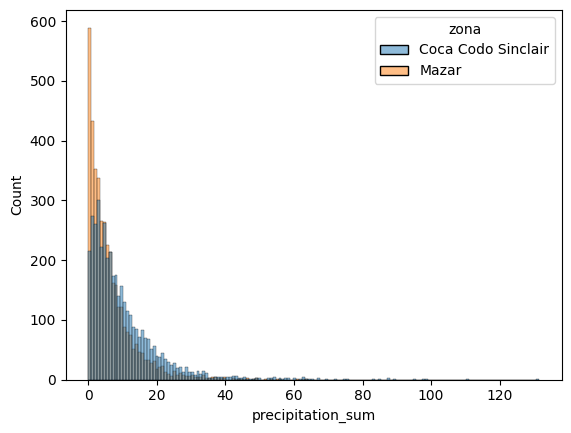

In [ ]:
sns.histplot(data=df, x="precipitation_sum", hue="zona")

El histograma confirma que la precipitación está concentrada en valores bajos y tiene una cola larga hacia la derecha. Coca Codo Sinclair tiene más días con lluvias intensas.

<Axes: xlabel='zona', ylabel='precipitation_sum'>

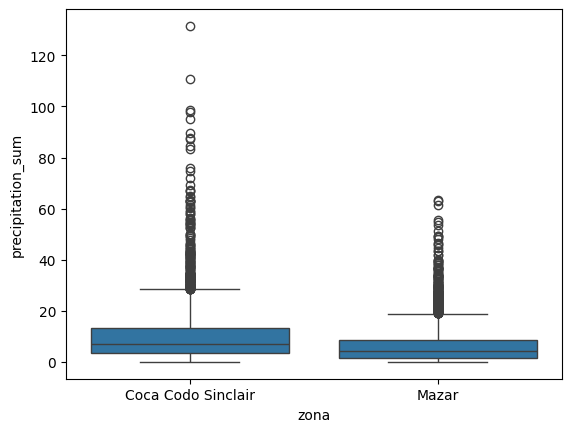

In [ ]:
sns.boxplot(data=df, x="zona", y="precipitation_sum")

In [ ]:
q = df.groupby("zona")["precipitation_sum"].quantile([0.25, 0.75]).unstack()

In [ ]:
limite = q[0.75] + 1.5 * (q[0.75] - q[0.25])

In [ ]:
(df["precipitation_sum"] > df["zona"].map(limite)).groupby(df["zona"]).sum()

,0
zona,
Coca Codo Sinclair,196
Mazar,236


Según el criterio del rango intercuartílico, hay 196 días atípicos en Coca Codo Sinclair (más de 28,6 mm) y 236 en Mazar (más de 18,9 mm). Estos valores no son errores: corresponden a días de lluvias fuertes, que son físicamente posibles y justamente los eventos que interesa estudiar. Por eso se conservan.

<Axes: xlabel='time'>

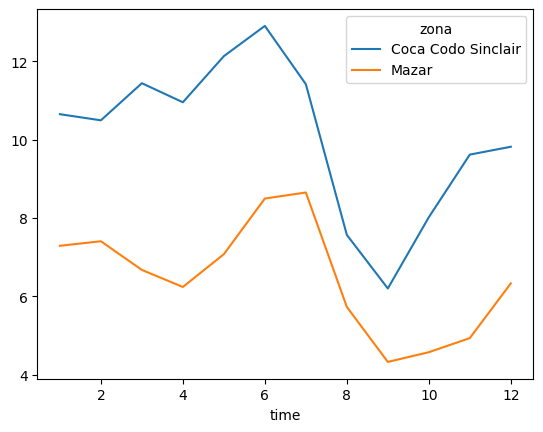

In [ ]:
df.groupby([pd.to_datetime(df["time"]).dt.month, "zona"])["precipitation_sum"].mean().unstack().plot()

La lluvia cambia según el mes. En Coca Codo Sinclair los meses más lluviosos son mayo y junio, y en Mazar son junio y julio. En ambas zonas septiembre es el mes más seco. Esto indica que el mes del año puede aportar información al modelo.

<Axes: >

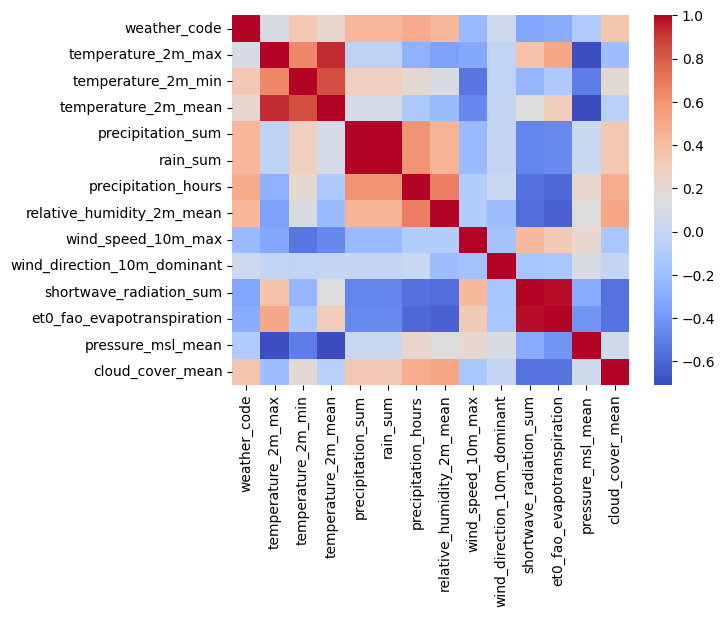

In [ ]:
sns.heatmap(df.select_dtypes("number").corr(), cmap="coolwarm")

La precipitación se relaciona positivamente con las horas de precipitación (0,60), la humedad (0,45) y la nubosidad (0,33), y negativamente con la radiación solar (-0,49) y la evapotranspiración (-0,46). También se observan variables casi repetidas: la radiación y la evapotranspiración tienen una correlación de 0,98, y la temperatura media tiene 0,93 con la máxima.

## 3. Limpieza y preparación

In [ ]:
df = df.rename(columns={"time": "fecha", "weather_code": "codigo_clima", "temperature_2m_max": "temp_max", "temperature_2m_min": "temp_min", "temperature_2m_mean": "temp_media", "precipitation_sum": "precipitacion", "rain_sum": "lluvia", "precipitation_hours": "horas_precipitacion", "relative_humidity_2m_mean": "humedad_media", "wind_speed_10m_max": "viento_max", "wind_direction_10m_dominant": "direccion_viento", "shortwave_radiation_sum": "radiacion", "et0_fao_evapotranspiration": "evapotranspiracion", "pressure_msl_mean": "presion_media", "cloud_cover_mean": "nubosidad_media"})

In [ ]:
df["fecha"] = pd.to_datetime(df["fecha"])

In [ ]:
df = df.drop(columns=["lluvia", "codigo_clima", "direccion_viento"])

Se eliminan tres columnas: `lluvia` porque es idéntica a `precipitacion`, `codigo_clima` porque se deriva de la precipitación del mismo día, y `direccion_viento` porque es un ángulo de 0 a 360 grados en el que 0 y 360 representan lo mismo, por lo que no puede usarse directamente como número.

In [ ]:
df["mes"] = df["fecha"].dt.month

In [ ]:
df = df.sort_values(["zona", "fecha"])

In [ ]:
df["precip_manana"] = df.groupby("zona")["precipitacion"].shift(-1)

In [ ]:
df = df.dropna(subset=["precip_manana"])

In [ ]:
df["lluvia_manana"] = (df["precip_manana"] >= 5).astype(int)

In [ ]:
df = df.drop(columns="precip_manana")

Se crea la variable objetivo `lluvia_manana`, que vale 1 si al día siguiente caen 5 mm o más y 0 en caso contrario. Se calcula por separado en cada zona. El último día de cada zona no tiene día siguiente, por lo que se eliminan esas 2 filas.

In [ ]:
df.groupby("zona")["lluvia_manana"].mean()

,lluvia_manana
zona,
Coca Codo Sinclair,0.632811
Mazar,0.456062


Con el umbral de 5 mm, el 63 % de los días de Coca Codo Sinclair y el 46 % de los días de Mazar tienen lluvia significativa al día siguiente. Con un umbral de 1 mm las clases quedaban muy desbalanceadas (94 % y 84 %), y un modelo que siempre respondiera "llueve" parecería bueno sin aprender nada.

In [ ]:
df.corr(numeric_only=True)["lluvia_manana"].sort_values()

,lluvia_manana
radiacion,-0.168526
evapotranspiracion,-0.154595
viento_max,-0.109861
mes,-0.101339
presion_media,-0.100683
temp_max,0.091513
temp_media,0.147038
nubosidad_media,0.190498
temp_min,0.220214
humedad_media,0.295004


Las variables del día actual que más se relacionan con la lluvia del día siguiente son las horas de precipitación, la humedad y la precipitación. Las relaciones son moderadas, lo que anticipa que la predicción no será perfecta. La presión atmosférica casi no se relaciona con la lluvia del día siguiente, algo que también se ha observado en estudios de climas tropicales.

## 4. Comparación antes y después

In [ ]:
pd.DataFrame({"antes": [len(original), original.duplicated(["zona", "time"]).sum(), original.isna().sum().sum(), original.shape[1], str(original["time"].dtype)], "despues": [len(df), df.duplicated(["zona", "fecha"]).sum(), df.isna().sum().sum(), df.shape[1], str(df["fecha"].dtype)]}, index=["registros", "duplicados", "faltantes", "columnas", "tipo de fecha"])

,antes,despues
registros,8036,8034
duplicados,0,0
faltantes,0,0
columnas,16,15
tipo de fecha,object,datetime64[ns]


In [ ]:
df.dtypes

,0
zona,object
fecha,datetime64[ns]
temp_max,float64
temp_min,float64
temp_media,float64
precipitacion,float64
horas_precipitacion,float64
humedad_media,int64
viento_max,float64
radiacion,float64


In [ ]:
df.head()

,zona,fecha,temp_max,temp_min,temp_media,precipitacion,horas_precipitacion,humedad_media,viento_max,radiacion,evapotranspiracion,presion_media,nubosidad_media,mes,lluvia_manana
0,Coca Codo Sinclair,2015-01-01,21.3,15.1,18.4,2.4,6.0,83,8.2,19.34,3.47,1014.7,58,1,0
1,Coca Codo Sinclair,2015-01-02,21.2,14.3,17.8,0.0,0.0,78,7.7,12.22,2.44,1015.0,79,1,0
2,Coca Codo Sinclair,2015-01-03,21.5,17.2,19.1,0.0,0.0,70,6.9,14.84,2.94,1015.0,81,1,0
3,Coca Codo Sinclair,2015-01-04,19.9,17.0,18.3,0.4,2.0,75,4.3,7.77,1.67,1016.1,99,1,0
4,Coca Codo Sinclair,2015-01-05,21.5,16.0,18.5,0.5,3.0,79,7.6,14.17,2.66,1015.8,76,1,0


In [ ]:
df.to_csv("hidroclima_preparado.csv", index=False)

## 5. Variables para Machine Learning
- **Variable objetivo (y):** `lluvia_manana`.
- **Variables de entrada (X):** `zona`, `mes`, `precipitacion`, `horas_precipitacion`, `humedad_media`, `nubosidad_media`, `temp_max`, `temp_min`, `presion_media`, `radiacion`, `viento_max`.
- **No se usan:** `fecha` (solo identifica el día; su información útil se conserva en `mes`), `temp_media` (correlación de 0,93 con la máxima), `evapotranspiracion` (correlación de 0,98 con la radiación) y cualquier dato del día siguiente, porque revelaría el resultado.